# **Import Libraries**

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load dataset
df = pd.read_csv('data.csv', encoding='ISO-8859-1')

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())
print("\nMissing Values:")
print(df.isnull().sum())


Dataset loaded successfully!
Shape: (150444, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  

Missing Values:
InvoiceNo          0
StockCode          0
Description      598
Quantity           0
InvoiceDate        1
UnitPrice          1
CustomerID     46504
C

# **Data cleaning**

In [4]:

# Remove missing customer IDs
df = df.dropna(subset=['CustomerID'])

# Remove cancelled invoices
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# Keep only positive quantity and price
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Convert date
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Calculate total sales
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

print("Cleaned Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())


Cleaned Dataset Shape: (101330, 9)
Missing Values: 0


# **RFM Analysis**

In [5]:

# Reference date
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate RFM values
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

print("RFM Analysis:")
print(rfm.head())

print("\nRFM Statistics:")
print(rfm.describe())


RFM Analysis:
            Recency  Frequency  Monetary
CustomerID                              
12346.0          81          1  77183.60
12347.0           2          3   1823.43
12348.0           4          3   1487.24
12350.0          65          1    334.40
12352.0          17          5   1561.81

RFM Statistics:
           Recency    Frequency      Monetary
count  2232.000000  2232.000000   2232.000000
mean     47.974462     2.255376   1038.897164
std      38.875876     3.071568   3444.823341
min       1.000000     1.000000      0.850000
25%      16.000000     1.000000    223.602500
50%      38.000000     1.000000    409.300000
75%      73.000000     2.000000    898.245000
max     129.000000    58.000000  81612.620000


# **Select features and scale data**

In [6]:

# Select behavioural features
features = rfm[['Recency', 'Frequency', 'Monetary']].copy()

# Log transformation reduces skewness
features = np.log1p(features)

# Standardize features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

print("Feature scaling completed!")


Feature scaling completed!


# **Elbow Method**

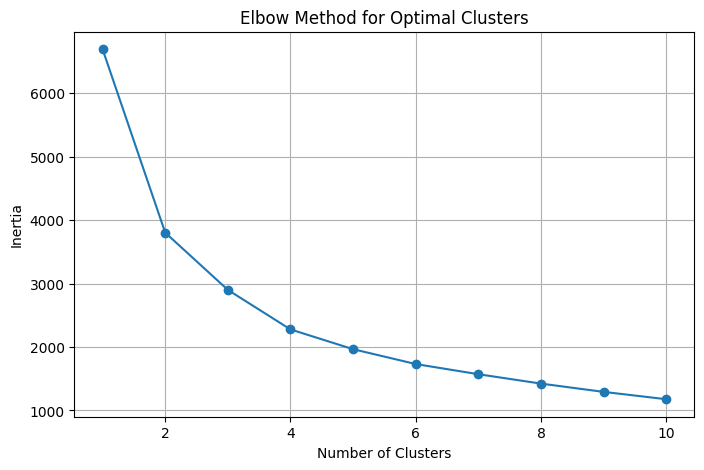

In [7]:

inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(scaled_features)
    inertia.append(model.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(1,11), inertia, marker='o')
plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()


# **Apply K-Means Clustering**

In [8]:

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm['Cluster'] = kmeans.fit_predict(scaled_features)

print("Customer Clustering Completed!")
print(rfm.head())

print("\nCluster Counts:")
print(rfm['Cluster'].value_counts())


Customer Clustering Completed!
            Recency  Frequency  Monetary  Cluster
CustomerID                                       
12346.0          81          1  77183.60        1
12347.0           2          3   1823.43        2
12348.0           4          3   1487.24        2
12350.0          65          1    334.40        3
12352.0          17          5   1561.81        2

Cluster Counts:
Cluster
3    940
1    574
0    442
2    276
Name: count, dtype: int64


# **Visualize customer clusters**

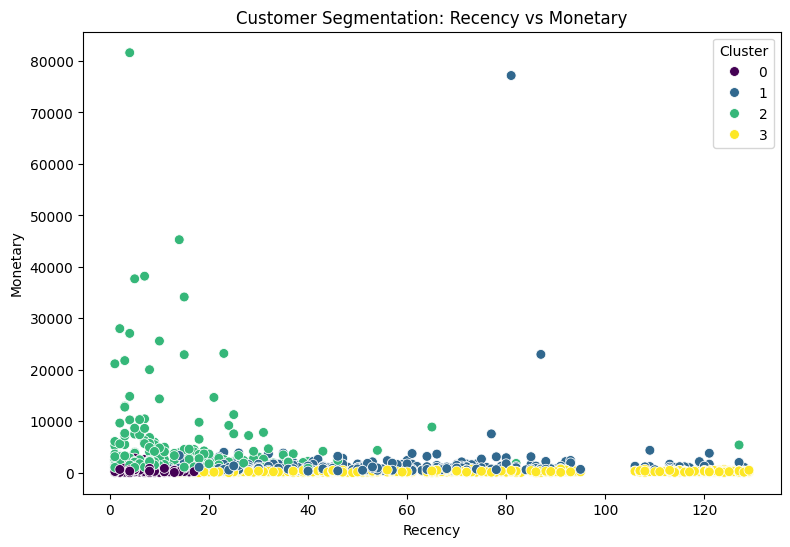

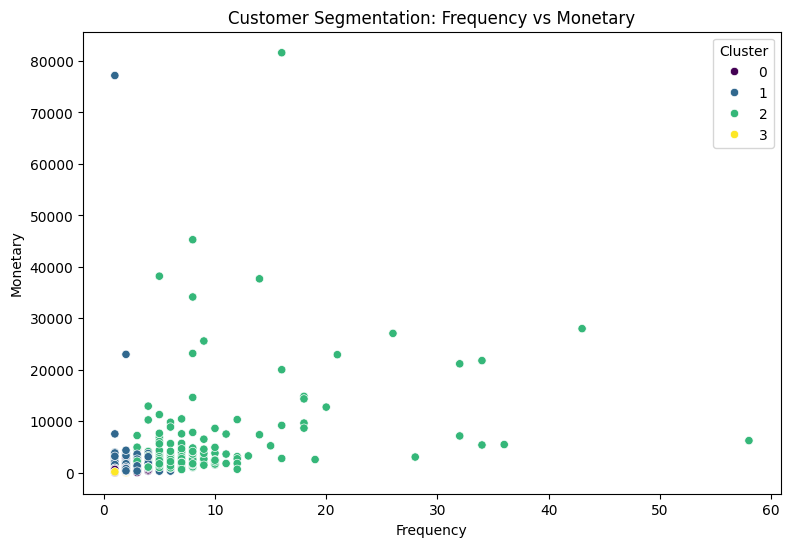

In [9]:

plt.figure(figsize=(9,6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=50
)

plt.title('Customer Segmentation: Recency vs Monetary')
plt.show()


plt.figure(figsize=(9,6))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='viridis'
)

plt.title('Customer Segmentation: Frequency vs Monetary')
plt.show()


# **Cluster profiling**

In [10]:


cluster_profile = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).round(2)

print("Customer Segment Profiles:")
print(cluster_profile)


Customer Segment Profiles:
         Recency  Frequency  Monetary
Cluster                              
0           9.67       1.54    476.38
1          47.57       2.24   1179.26
2          13.40       7.50   4345.56
3          76.38       1.06    246.80


# **Number of customers in each cluster**

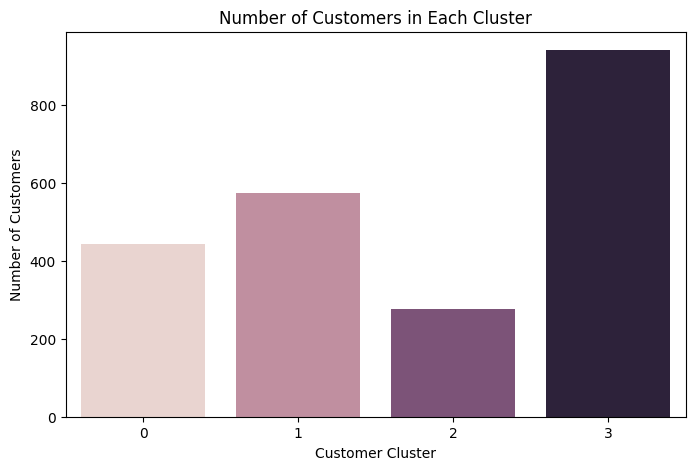

In [11]:

plt.figure(figsize=(8,5))

sns.countplot(data=rfm, x='Cluster', hue='Cluster', legend=False)

plt.title('Number of Customers in Each Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')
plt.show()


# **Business recommendations**


# Customer Segmentation – Conclusion

## Key Findings

1. Customers were segmented using RFM analysis.
2. Recency measures how recently customers purchased.
3. Frequency measures the number of unique purchases.
4. Monetary measures total customer spending.
5. K-Means clustering grouped customers based on their purchasing behaviour.

## Marketing Recommendations

1. Reward high-value customers with loyalty benefits.
2. Offer discounts to customers who have not purchased recently.
3. Encourage frequent customers to purchase more products.
4. Use targeted campaigns for different customer segments.
5. Monitor customer behaviour to improve retention.

## Conclusion

Customer segmentation helps businesses understand purchasing behaviour and develop targeted marketing strategies. RFM analysis and K-Means clustering provide useful insights for customer retention and business growth.
